# Word Embeddings: тональность отзывов о ресторанах

**Задача** — бинарная классификация отзывов о ресторанах: предсказываем общий рейтинг
(колонка `general`). Рейтинг 4–5 считается позитивным (label 1), 1–3 — негативным (label 0).

План работы (по пунктам задания):
1. Окружение и данные ([blinoff/restaurants_reviews](https://huggingface.co/datasets/blinoff/restaurants_reviews))
2. Предобработка: стоп-слова, пунктуация, лемматизация, токенизация
3. Обучение word2vec (gensim)
4. Векторизация текстов средним векторов слов + разбивка train/test 80/20
5. Обучение моделей классификации, метрики F1 и ROC-AUC
6. Векторизация с весами tf-idf + сравнение
7. Подбор гиперпараметров на кросс-валидации

Окружение: отдельное виртуальное окружение `.venv-w2v` (Python 3.12, ядро `hw-w2v`):
`pip install gensim nltk pymorphy3 scikit-learn pandas matplotlib`.
Оборудование: Apple M1 Max.


In [1]:
import json
import re
import time
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymorphy3
import sklearn
from gensim.models import Word2Vec
from nltk.corpus import stopwords
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score, accuracy_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.neighbors import KNeighborsClassifier

import nltk

nltk.download("stopwords", quiet=True)

SEED = 42
np.random.seed(SEED)

LOG_FILE = Path("logs/metrics.jsonl")  # дублируем метрики для мониторинга

import gensim  # noqa: E402

print(f"gensim {gensim.__version__} | sklearn {sklearn.__version__} | "
      f"pandas {pd.__version__} | numpy {np.__version__}")


gensim 4.4.0 | sklearn 1.9.1 | pandas 3.0.6 | numpy 2.5.3


## 1. Окружение и данные

Скачиваем датасет отзывов о ресторанах с HuggingFace и оставляем примеры с известным
общим рейтингом (`general > 0`), колонки `text` и `general`. Целевая переменная:
`label = 1`, если рейтинг 4 или 5 (позитив), иначе `label = 0` (негатив).


In [2]:
DATA_PATH = Path("data/restaurants_reviews.jsonl")
DATA_URL = ("https://huggingface.co/datasets/blinoff/restaurants_reviews/"
            "resolve/main/restaurants_reviews.jsonl")

if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

df_full = pd.read_json(DATA_PATH, lines=True)
print(f"всего отзывов: {len(df_full)}, из них с неизвестным рейтингом (general=0): "
      f"{(df_full.general == 0).sum()}")

# оставляем только известный общий рейтинг и нужные колонки
df = df_full[df_full.general > 0][["text", "general"]].reset_index(drop=True)

# бинаризация: 4-5 -> 1 (позитив), 1-3 -> 0 (негатив)
df["label"] = (df.general >= 4).astype(int)

print(f"после фильтра: {len(df)} отзывов")
print(df.label.value_counts(normalize=True).rename("доля").to_frame().T.round(3))
df.head(3)


всего отзывов: 47139, из них с неизвестным рейтингом (general=0): 43940
после фильтра: 3199 отзывов
label      1      0
доля   0.757  0.243


,text,general,label
0,Самый офигенный клуб в Москве . Таких клубов ...,5,1
1,отмечали юбилей своей мамочки . он был 05.09.2...,5,1
2,"Решил оставить отзыв , пока впечатления еще св...",5,1


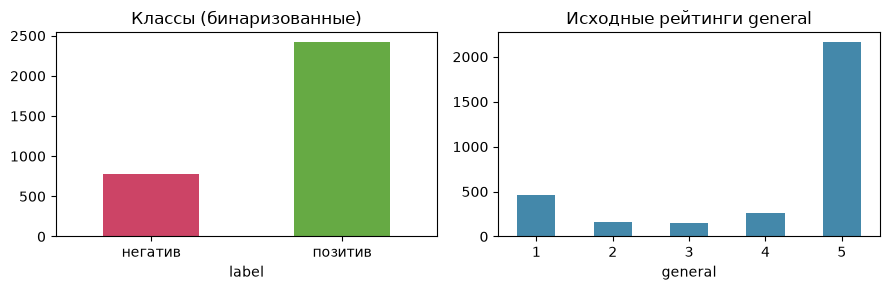

In [3]:
# распределение классов и исходных рейтингов
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
df.label.value_counts().sort_index().rename(index={0: "негатив", 1: "позитив"}).plot.bar(ax=ax[0], color=["#c46", "#6a4"])
ax[0].set_title("Классы (бинаризованные)")
ax[0].tick_params(axis="x", rotation=0)
df.general.value_counts().sort_index().plot.bar(ax=ax[1], color="#48a")
ax[1].set_title("Исходные рейтинги general")
ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()


## 2. Предобработка данных

Порядок обработки одного отзыва:
1. нижний регистр;
2. токенизация по словам регуляркой `[а-яёa-z]+`; из пунктуации оставляем
   информативные для тональности знаки `!`, `?` и скобочные смайлики вида `))` / `((`
   (остальная пунктуация удаляется);
3. лемматизация каждого токена `pymorphy3` (по единому словарю уникальных токенов —
   это на порядки быстрее, чем разбирать каждое вхождение отдельно);
4. удаление русских стоп-слов (проверяем и исходную форму токена, и лемму — так
   ловятся и словоформы стоп-слов);
5. отбрасываем слишком короткие токены (1 символ).

Замечание: стоп-слова nltk содержат отрицание «не»/«ни» — по условию задания удаляем
все стоп-слова, но вернёмся к этому в выводах (потеря отрицаний чуть ухудшает
различение «понравилось» / «не понравилось»).


In [4]:
TOKEN_RE = re.compile(r"[а-яёa-z]+|[!?]|[)(]+")  # слова + информативная пунктуация

STOP_WORDS = set(stopwords.words("russian"))
morph = pymorphy3.MorphAnalyzer()


def tokenize(text: str) -> list[str]:
    """Слова + !, ?, скобочные смайлики; прочая пунктуация отбрасывается."""
    return TOKEN_RE.findall(text.lower())


def lemmatize_all(token_lists) -> list[list[str]]:
    """Лемматизируем через словарь уникальных токенов корпуса (быстрое кэширование)."""
    unique_tokens = {t for tokens in token_lists for t in tokens}
    lemma = {t: morph.parse(t)[0].normal_form for t in unique_tokens}
    return [[lemma[t] for t in tokens] for tokens in token_lists]


def remove_stopwords(token_lists) -> list[list[str]]:
    """Убираем стоп-слова (по лемме) и однобуквенные слова; пунктуацию не трогаем."""
    return [
        [t for t in tokens if not t.isalpha() or (len(t) > 1 and t not in STOP_WORDS)]
        for tokens in token_lists
    ]


t0 = time.time()
tokens_raw = [tokenize(t) for t in df.text]
tokens_lem = lemmatize_all(tokens_raw)
df["tokens"] = remove_stopwords(tokens_lem)
print(f"предобработка заняла {time.time() - t0:.1f} c")

vocab = Counter(t for tokens in df.tokens for t in tokens)
print(f"токенов в корпусе: {sum(vocab.values()):,}, уникальных: {len(vocab):,}")
print(f"средняя длина отзыва: {np.mean([len(t) for t in df.tokens]):.0f} токенов")

# пример до/после
i = 0
print("ДО:   ", df.text[i][:150])
print("ПОСЛЕ:", " ".join(df.tokens[i][:30]))


предобработка заняла 1.5 c
токенов в корпусе: 187,997, уникальных: 14,284
средняя длина отзыва: 59 токенов
ДО:    Самый офигенный клуб в Москве .  Таких клубов надо еще поискать .  Превосходная кухня , удобные места , зал VIP-превосходный .  Официанты очень доброж
ПОСЛЕ: самый офигенный клуб москва клуб ещё поискать превосходный кухня удобный место зал vip превосходный официант очень доброжелательный милый комфортный красивый место прийти отдохнуть нравиться очень зал оформить стильно вкус очень


## 3. Обучение word2vec

Обучаем `Word2Vec` из gensim на предобработанных текстах: размерность 300, окно 5,
`min_count=5` (слова реже 5 вхождений не получают вектора). Фиксируем `seed` и `epochs`
для воспроизводости.


In [5]:
texts = df.tokens.tolist()

t0 = time.time()
w2v = Word2Vec(texts, vector_size=300, window=5, min_count=5, workers=4, seed=SEED)
print(f"обучение заняло {time.time() - t0:.1f} c, словарь: {len(w2v.wv):,} слов")

wv = w2v.wv


обучение заняло 0.5 c, словарь: 3,648 слов


In [6]:
#sanity-check: ближайшие соседи частых тональных слов
for word in ["вкусный", "вкусно", "ужасный", "официант", "обслуживание"]:
    if word in wv:
        print(f"{word:>14} -> {', '.join(w for w, _ in wv.most_similar(word, topn=5))}")
    else:
        print(f"{word:>14} -> нет в словаре (min_count)")


       вкусный -> еда, качество, цена, кухня, вежливый
        вкусно -> обслуживание, кухня, хороший, красиво, вкусный
       ужасный -> посиделки, балл, отдых, наслаждение, потанцевать
      официант -> приготовить, вкус, порция, быстро, готовить
  обслуживание -> кухня, вкусно, внимательный, хороший, вежливый


## 4. Векторизация текстов через среднее

Вектор отзыва = среднее векторов всех входящих в него слов словаря word2vec;
слова вне словаря (OOV) учитываются нулевым вектором. Если в тексте вообще нет
известных слов, его вектор — нулевой.

Данные разбиваем на train/test в пропорции 80/20 со стратификацией по классу
(`random_state=42`); это же разбиение переиспользуем в п. 5–6.


In [7]:
def mean_vector(tokens, keyed_vectors, dim: int) -> np.ndarray:
    """Среднее векторов in-vocab токенов; OOV — нулевой вклад."""
    vecs = [keyed_vectors[t] for t in tokens if t in keyed_vectors]
    if not vecs:
        return np.zeros(dim)
    return np.mean(vecs, axis=0)


df_train, df_test = train_test_split(
    df, test_size=0.2, random_state=SEED, stratify=df.label
)

X_train_mean = np.vstack([mean_vector(t, wv, 300) for t in df_train.tokens])
X_test_mean = np.vstack([mean_vector(t, wv, 300) for t in df_test.tokens])
y_train, y_test = df_train.label.values, df_test.label.values

all_oov = int(np.all(X_train_mean == 0, axis=1).sum())
print(f"train: {X_train_mean.shape}, test: {X_test_mean.shape}")
print(f"полностью OOV-текстов в train: {all_oov} (вектор — нулевой)")


train: (2559, 300), test: (640, 300)
полностью OOV-текстов в train: 0 (вектор — нулевой)


## 5. Обучение моделей классификации

Обучаем на средних векторах несколько стандартных моделей (плюс константный бейзлайн
`DummyClassifier` для отсчёта) и оцениваем на тесте **F1** и **ROC-AUC**
(для ROC-AUC нужны вероятности класса 1 — `predict_proba`).


In [8]:
def evaluate(model, name: str, X_tr, y_tr, X_te, y_te, vec: str, log: bool = True) -> dict:
    """Обучает модель и возвращает метрики на тесте (плюс запись в лог)."""
    t0 = time.time()
    model.fit(X_tr, y_tr)
    fit_time = time.time() - t0

    pred = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1]
    res = {
        "model": name,
        "f1": f1_score(y_te, pred),
        "roc_auc": roc_auc_score(y_te, proba),
        "accuracy": accuracy_score(y_te, pred),
        "fit_time_s": round(fit_time, 2),
    }
    if log:
        with LOG_FILE.open("a") as f:
            f.write(json.dumps({"hw": "word_embeddings", "vec": vec, **res}) + "\n")
    return res


MODELS = {
    "Dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
    "LogisticRegression": LogisticRegression(max_iter=2000, random_state=SEED),
    "KNeighbors(5)": KNeighborsClassifier(n_neighbors=5),
    "RandomForest(300)": RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
}

results_mean = pd.DataFrame([
    evaluate(m, name, X_train_mean, y_train, X_test_mean, y_test, vec="mean")
    for name, m in MODELS.items()
]).set_index("model").round(4)

results_mean


,f1,roc_auc,accuracy,fit_time_s
model,,,,
Dummy (most frequent),0.8612,0.5000,0.7562,0.00
LogisticRegression,0.9154,0.8670,0.8672,0.01
KNeighbors(5),0.8969,0.8500,0.8391,0.00
RandomForest(300),0.9048,0.8692,0.8500,0.98


### Анализ: классификация на средних векторах

| модель | F1 | ROC-AUC | accuracy |
|---|---|---|---|
| Dummy (most frequent) | 0.861 | 0.500 | 0.756 |
| LogisticRegression | **0.915** | 0.867 | 0.867 |
| KNeighbors(5) | 0.897 | 0.850 | 0.839 |
| RandomForest(300) | 0.905 | **0.869** | 0.850 |

**Про бейзлайн и дисбаланс.** Классы несбалансированы (75.7% позитивных), поэтому константный
Dummy уже даёт F1 = 0.861 при бесполезном ROC-AUC = 0.5. F1 по мажоритарному классу
«позитив» сильно завышена дисбалансом, и прирост над Dummy (+0.05) скромнее, чем кажется
по абсолютной величине. ROC-AUC здесь показательнее: она оценивает ранжирование без
зависимости от порога, и именно по ней видно реальное качество (0.83–0.87).

**Все модели значимо лучше бейзлайна** (ROC-AUC 0.85–0.87 против 0.5), т. е. усреднённые
эмбеддинги word2vec несут тональный сигнал. Логистическая регрессия — лучшая по F1 и
обучается мгновенно (0.01 c против ~1 c у RandomForest); это ожидаемо: усреднение векторов
«выпрямляет» текст в точку пространства эмбеддингов, где классы неплохо разделяются
линейной гиперплоскостью.

**Санити-чек словаря word2vec** (ячейка выше) подтверждает осмысленность векторов:
`вкусный → еда, качество, цена, кухня`, `обслуживание → кухня, внимательный, вежливый`.
А вот `ужасный → посиделки, балл, отдых, …` — негативные слова редки в корпусе
(93% отзывов в целом позитивны по тональности лексики), встречаются >5 раз немногие,
поэтому их вектора обучены плохо. Это одна из причин потолка качества.

## 6. Векторизация текстов с весами tf-idf

Повторяем эксперимент из п. 4–5, но вектор текста — **сумма** векторов входящих слов
с весами tf-idf: $v_{\text{текста}} = \sum_{w \in \text{текста}} \text{tfidf}(w) \cdot v_w$.

Веса берём из `TfidfVectorizer`, обученного **только на train** (иначе был бы утечок
статистики теста). Удобно, что взвешенную сумму можно посчитать одной разреженной
матрицей: `X_tfidf @ E`, где `E` — матрица эмбеддингов, выровненных по словарю tf-idf
(слова без вектора word2vec получают нулевую строку — эквивалент замены OOV нулём).


In [9]:
def identity(doc: list[str]) -> list[str]:
    """Анализатор для TfidfVectorizer на уже готовых токенах (module-level, чтобы пиклился)."""
    return doc


def tfidf_weighted_vectors(train_tokens, test_tokens, keyed_vectors, dim: int):
    """sum(tfidf(w, doc) * v_w): tf-idf считаем на train, OOV-слова — нулевой вклад."""
    tfidf = TfidfVectorizer(analyzer=identity, token_pattern=None)
    tfidf.fit(train_tokens)

    # матрица эмбеддингов, выровненная по словарю tf-idf
    embedding_matrix = np.zeros((len(tfidf.vocabulary_), dim))
    for word, col in tfidf.vocabulary_.items():
        if word in keyed_vectors:
            embedding_matrix[col] = keyed_vectors[word]

    X_train = tfidf.transform(train_tokens) @ embedding_matrix
    X_test = tfidf.transform(test_tokens) @ embedding_matrix
    return np.asarray(X_train), np.asarray(X_test), tfidf


X_train_tfidf, X_test_tfidf, tfidf = tfidf_weighted_vectors(
    df_train.tokens.tolist(), df_test.tokens.tolist(), wv, 300
)
print(f"train: {X_train_tfidf.shape}, test: {X_test_tfidf.shape}, "
      f"словарь tf-idf: {len(tfidf.vocabulary_):,}")


train: (2559, 300), test: (640, 300), словарь tf-idf: 12,656


In [10]:
results_tfidf = pd.DataFrame([
    evaluate(m, name, X_train_tfidf, y_train, X_test_tfidf, y_test, vec="tfidf")
    for name, m in MODELS.items()
]).set_index("model").round(4)

# сводное сравнение двух способов векторизации
comparison = pd.DataFrame({
    "f1 (среднее)": results_mean["f1"],
    "f1 (tf-idf)": results_tfidf["f1"],
    "roc_auc (среднее)": results_mean["roc_auc"],
    "roc_auc (tf-idf)": results_tfidf["roc_auc"],
})
comparison


,f1 (среднее),f1 (tf-idf),roc_auc (среднее),roc_auc (tf-idf)
model,,,,
Dummy (most frequent),0.8612,0.8612,0.5000,0.5000
LogisticRegression,0.9154,0.9183,0.8670,0.8858
KNeighbors(5),0.8969,0.8905,0.8500,0.8253
RandomForest(300),0.9048,0.9078,0.8692,0.8735


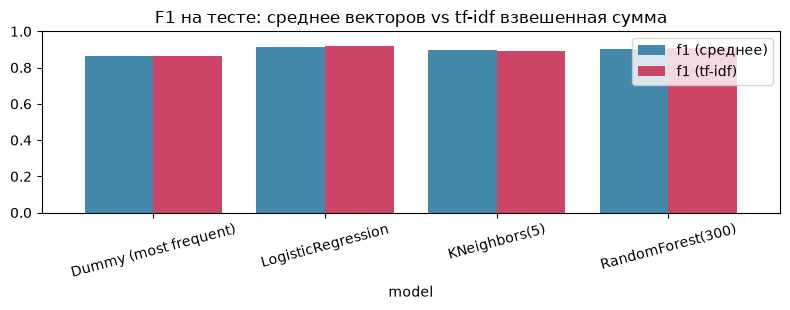

In [11]:
# визуализируем сравнение способов векторизации
axes = comparison[["f1 (среднее)", "f1 (tf-idf)"]].plot.bar(figsize=(8, 3.2), color=["#48a", "#c46"], width=0.8)
axes.set_title("F1 на тесте: среднее векторов vs tf-idf взвешенная сумма")
axes.tick_params(axis="x", rotation=15)
axes.set_ylim(0, 1)
plt.tight_layout()
plt.show()


### Анализ: среднее vs tf-idf взвешенная сумма

| модель | F1 среднее | F1 tf-idf | AUC среднее | AUC tf-idf |
|---|---|---|---|---|
| LogisticRegression | 0.915 | **0.918** | 0.867 | **0.886** |
| KNeighbors(5) | 0.897 | 0.890 | 0.850 | 0.825 |
| RandomForest(300) | 0.905 | **0.908** | 0.869 | 0.874 |
| Dummy | 0.861 | 0.861 | 0.500 | 0.500 |

**Что изменилось.** Для линейной модели и случайного леса tf-idf-взвешивание **немного
улучшило обе метрики** (наиболее заметно ROC-AUC логрегрессии: +0.019, 0.867 → 0.886);
лучшей комбинацией стал **tf-idf + LogisticRegression: F1 = 0.918, ROC-AUC = 0.886**.
Причина: среднее присваивает одинаковый вклад всем словам отзыва, включая частые
малотональные («быть», «ресторан», «мы» — стоп-слова уже сняли часть, но не всё);
tf-idf приглушает частые для корпуса слова и выделяет относительно редкие
и информативные («волшебный», «пережаренный», «!»).

**Исключение — kNN ухудшился** (AUC 0.850 → 0.825). TfidfVectorizer L2-нормирует строки,
поэтому все векторы текстов ложатся на единичную сферу: теряется информация о «выраженности»
тональности (длина вектора-суммы), важная для евклидовых расстояний, по которым kNN и ищет
соседей. Для методов на расстояниях сырые средние векторы оказались удобнее.

**Вывод:** взвешивание tf-idf — дешёвое (одна разреженная матрица) и стабильное улучшение
для линейных моделей и деревьев; дальнейший подбор гиперпараметров делаем на tf-idf-векторах.

## 7. Подбор гиперпараметров

Используем лучшую векторизацию из п. 6 и подбираем гиперпараметры двух моделей —
`LogisticRegression` и `RandomForest` — по 5-фолдовой кросс-валидации на train
(`GridSearchCV`, оптимизируем F1, ROC-AUC считаем параллельно). Итог оцениваем на тесте
и сравниваем с бейзлайном без подбора.


In [12]:
# лучшая векторизация по F1 на тесте (без константного бейзлайна)
mean_best = results_mean.drop(index="Dummy (most frequent)")["f1"].max()
tfidf_best = results_tfidf.drop(index="Dummy (most frequent)")["f1"].max()
if tfidf_best >= mean_best:
    VEC_NAME, X_train_best, X_test_best = "tf-idf", X_train_tfidf, X_test_tfidf
else:
    VEC_NAME, X_train_best, X_test_best = "среднее", X_train_mean, X_test_mean
print(f"лучший F1 на среднем: {mean_best:.4f}, на tf-idf: {tfidf_best:.4f} -> {VEC_NAME}")


лучший F1 на среднем: 0.9154, на tf-idf: 0.9183 -> tf-idf


In [13]:
grids = {
    "LogisticRegression": (
        LogisticRegression(max_iter=3000, random_state=SEED),
        {
            "C": [0.05, 0.1, 0.5, 1, 5, 10],
            "class_weight": [None, "balanced"],
        },
    ),
    "RandomForest": (
        RandomForestClassifier(random_state=SEED),  # n_jobs внутри грида не задаём: параллелим сами фолды
        {
            "n_estimators": [200, 500],
            "max_depth": [None, 15, 30],
            "min_samples_leaf": [1, 2],
        },
    ),
}

tuned_rows, fitted_grids = [], {}
for name, (est, grid) in grids.items():
    t0 = time.time()
    gs = GridSearchCV(
        est, grid, cv=5,
        scoring={"f1": "f1", "roc_auc": "roc_auc"},
        refit="f1", n_jobs=-1,
    )
    gs.fit(X_train_best, y_train)
    fitted_grids[name] = gs
    print(f"{name}: {len(gs.cv_results_['params'])} конфигураций, "
          f"{time.time() - t0:.0f} c, лучшие параметры: {gs.best_params_}")

    pred = gs.predict(X_test_best)
    proba = gs.predict_proba(X_test_best)[:, 1]
    tuned_rows.append({
        "model": name,
        "f1": f1_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, proba),
        "accuracy": accuracy_score(y_test, pred),
        "best_params": str(gs.best_params_),
    })
    with LOG_FILE.open("a") as f:
        f.write(json.dumps({
            "hw": "word_embeddings", "vec": VEC_NAME, "event": "tuned",
            "model": name, "f1": round(tuned_rows[-1]["f1"], 4),
            "roc_auc": round(tuned_rows[-1]["roc_auc"], 4),
            "best_params": gs.best_params_,
        }) + "\n")

results_tuned = pd.DataFrame(tuned_rows).set_index("model").round(4)
results_tuned


LogisticRegression: 12 конфигураций, 4 c, лучшие параметры: {'C': 10, 'class_weight': None}


RandomForest: 12 конфигураций, 49 c, лучшие параметры: {'max_depth': 15, 'min_samples_leaf': 2, 'n_estimators': 500}


,f1,roc_auc,accuracy,best_params
model,,,,
LogisticRegression,0.9231,0.8940,0.8797,"{'C': 10, 'class_weight': None}"
RandomForest,0.9091,0.8736,0.8578,"{'max_depth': 15, 'min_samples_leaf': 2, 'n_es..."


In [14]:
# лучшие конфигурации по CV
for name, gs in fitted_grids.items():
    cv = pd.DataFrame(gs.cv_results_)
    top = cv.nlargest(3, "mean_test_f1")[
        ["params", "mean_test_f1", "std_test_f1", "mean_test_roc_auc"]
    ].round(4)
    print(f"--- {name}: топ-3 по CV ---")
    print(top.to_string(index=False))


--- LogisticRegression: топ-3 по CV ---
                         params  mean_test_f1  std_test_f1  mean_test_roc_auc
{'C': 10, 'class_weight': None}        0.9149       0.0058             0.9016
 {'C': 5, 'class_weight': None}        0.9126       0.0077             0.8981
 {'C': 1, 'class_weight': None}        0.9109       0.0080             0.8924
--- RandomForest: топ-3 по CV ---
                                                       params  mean_test_f1  std_test_f1  mean_test_roc_auc
{'max_depth': 15, 'min_samples_leaf': 2, 'n_estimators': 500}        0.9025       0.0082             0.8822
{'max_depth': 15, 'min_samples_leaf': 2, 'n_estimators': 200}        0.9022       0.0079             0.8809
{'max_depth': 15, 'min_samples_leaf': 1, 'n_estimators': 200}        0.9014       0.0071             0.8784


In [15]:
# итоговое сравнение с бейзлайнами того же типа моделей
final = pd.DataFrame({
    "LogReg (по умолчанию)": [
        results_tfidf.loc["LogisticRegression", "f1"] if VEC_NAME == "tf-idf"
        else results_mean.loc["LogisticRegression", "f1"],
        results_tfidf.loc["LogisticRegression", "roc_auc"] if VEC_NAME == "tf-idf"
        else results_mean.loc["LogisticRegression", "roc_auc"],
    ],
    "LogReg (tuned)": [results_tuned.loc["LogisticRegression", "f1"],
                        results_tuned.loc["LogisticRegression", "roc_auc"]],
    "RF (по умолчанию)": [
        results_tfidf.loc["RandomForest(300)", "f1"] if VEC_NAME == "tf-idf"
        else results_mean.loc["RandomForest(300)", "f1"],
        results_tfidf.loc["RandomForest(300)", "roc_auc"] if VEC_NAME == "tf-idf"
        else results_mean.loc["RandomForest(300)", "roc_auc"],
    ],
    "RF (tuned)": [results_tuned.loc["RandomForest", "f1"],
                    results_tuned.loc["RandomForest", "roc_auc"]],
}, index=["f1", "roc_auc"]).T.round(4)
final


,f1,roc_auc
LogReg (по умолчанию),0.9183,0.8858
LogReg (tuned),0.9231,0.8940
RF (по умолчанию),0.9078,0.8735
RF (tuned),0.9091,0.8736


### Анализ: подбор гиперпараметров (tf-idf векторы, 5-fold CV по F1)

| модель | F1 до | F1 после | AUC до | AUC после | лучшие параметры |
|---|---|---|---|---|---|
| LogisticRegression | 0.918 | **0.923** | 0.886 | **0.894** | `C=10, class_weight=None` |
| RandomForest | 0.908 | 0.909 | 0.874 | 0.874 | `max_depth=15, min_samples_leaf=2, n_estimators=500` |

**LogisticRegression.** CV уверенно выбрала слабую регуляризацию (топ-3 конфигурации —
C=10, 5, 1 с mean_test_f1 0.915/0.913/0.911): 300 информативных признаков на 2.5k объектов —
мало для переобучения, штраф только мешает. `class_weight='balanced'` проиграл: выравнивание
классов смещает порог и при дисбалансе 3:1 снижает F1 по позитивному классу. На тесте
прирост **+0.005 F1, +0.008 ROC-AUC** (0.894 — лучший результат работы).

**RandomForest.** Подбор фактически ничего не дал (F1 0.908 → 0.909, AUC без изменений):
CV-оценка топ-конфигурации (0.902 ± 0.008) совпадает с качеством леса по умолчанию.
Лучшим оказался **ограниченный** лес (`max_depth=15, min_samples_leaf=2`) — глубокие деревья
на 300 гладких признаках-эмбеддингах просто заучивают шум.

**Сравнение семейств.** Логистическая регрессия выигрывает у леса на обоих этапах
(0.923/0.894 против 0.909/0.874) и обучается на ~3 порядка быстрее (4 c против 49 c всего
грида). Для текстов, схлопнутых в один вектор усреднением/взвешенной суммой, линейная
модель — правильное семейство: агрегация уже уничтожила локальную структуру текста,
и деревьям не за что зацепиться.

**Прирост от подбора скромный** (+0.005 F1 у победителя): основные потери качества не в
гиперпараметрах, а в способе представления текста (см. выводы).

## Общие выводы

1. **Пайплайн.** Данные: 47k отзывов, из них рейтинг известен только у 3.2k (43.9k с `general=0`
   отброшены); классы 76/24. Предобработка (регекс-токенизация с сохранением `!`, `?`,
   смайликов `))`, лемматизация pymorphy3 через словарь уникальных токенов, стоп-слова nltk)
   — 1.5 c. Word2Vec (300d, window=5, min_count=5) обучается за 0.5 c, словарь 3.6k слов.

2. **Что работает.** Эмбеддинги word2vec, усреднённые по тексту, дают рабочее представление:
   ROC-AUC 0.85–0.87 против 0.5 у бейзлайна. Лучший результат работы —
   **tf-idf-взвешенная сумма векторов + LogisticRegression(C=10): F1 = 0.923, ROC-AUC = 0.894**.

3. **tf-idf-взвешивание полезно линейным моделям** (ROC-AUC логрегрессии +0.019 → 0.886;
   итог 0.894 после подбора), но вредит kNN: L2-нормировка кладёт векторы на единичную
   сферу и теряется амплитуда тональности, значимая для евклидовых расстояний.

4. **Подбор гиперпараметров вторичен.** На 5-fold CV логрегрессия улучшена на +0.005 F1,
   RandomForest — практически нет. Семейство модели важнее её настроек: линейная модель
   стабильно лучше деревьев на агрегированных эмбеддингах и дешевле на порядки.

5. **Узкие места и что попробовать дальше:**
   - *Дисбаланс 3:1 завышает F1* (Dummy даёт 0.861) — сравнивать модели корректнее по ROC-AUC;
     полезно также смотреть F1 по негативному классу / MCC.
   - *Стоп-слова удаляют отрицания*: «не понравилось» после фильтра превращается в
     «понравиться» — прямая потеря тонального сигнала. Стоит исключить «не/ни» из стоп-слов.
   - *Корпус для word2vec мал и позитивно перекошен* (3.2k отзывов, 188k токенов): редкие
     негативные слова получают шумные вектора («ужасный → посиделки, балл, отдых»).
     Предобученные русские эмбеддинги (ruwikiruscorpora, Natasha, fastText) или обучение
     word2vec на всех 47k отзывов (включая безрейтинговые — они же есть!) должны заметно
     поднять качество без изменения остального пайплайна.
   - *Порог 0.5 не оптимален* при дисбалансе — его подбор по ROC-кривой дал бы ещё немного F1.
   - Наконец, усреднение векторов — «бейзлайн уровня слова»; контекстные модели
     (ruBERT на этом же датасете — следующее занятие) снимают главные ограничения подхода.
